## <font color=#0099CC>mIAx - Taller Renta Fija - ANÁLISIS CARTERA DE RENTA FIJA</font>

En esta práctica, desarrollaremos un análisis exahustivo de un universo de Renta Fija, en concreto, de bonos corporativos. Además, construiremos y analizaremos varias carteras. 

Para ello, contaremos con la siguiente información almacenada en la carpeta *data*:
- **Universo de bonos**, con sus características esenciales (fichero *universo.csv*)
- **Histórico de precios** de cierre del universo de bonos anterior (fichero *precios_historicos_universo.csv*)
- **Curva de tipos de interés €STR** (fichero *curvaESTR.csv*)
- **Histórico de precios de otros índices** que nos serán de utilidad (fichero *precios_historicos_varios.csv*):
    - Índices de crédito: ITRAXX Main y ITRAXX XOVER. Serán útiles para la cobertura del riesgo de crédito.
    - Futuros sobre el *Schatz* (DU1), *BOBL* (OE1) y *BUND* (RX1). Serán útiles para la cobertura de los tipos de interés.
    - Índice de crédito *RECMTREU*, que valdría como benchmark de las carteras que construyamos.

No necesariamente se usará toda toda la información.

📣 <font color=#CC6600>**¡NORMAS!**</font>

La práctica se puede hacer en grupos de hasta **3 personas** y deberá entregarse antes del **26 de noviembre**. 

**ENTREGABLES**: 
* **Carpeta .zip** con el nombre del capitán del grupo.
* La carpeta debe mantener la estructura original.
* Los ficheros **funciones_aux.py** y **analisis_cartera.ipynb** deben completarse según se considere. 
* Deberán ser ejecutables y **enviarse ya debidamente ejecutados** y con los **resultados guardados**.
* Todo el **código debe estar comentado y razonado.**
* Las **celdas de texto deben responder explícitamente a las preguntas realizadas.**
* En la subcarpeta **"results" deberán estar los ficheros .csv** que se piden en los diferentes apartados.

Cada grupo expondrá una parte de los ejercicios en la clase del día 26, donde la resolveremos juntos a modo de taller. Esta exposición contará hasta **1 punto** de la nota final.
Cada apartado de esta práctica también contará hasta **1 punto** de la nota final.

Además, se valorará positivamente para la práctica la participación en las clases.

📣 <font color=#CC6600>**¡IMPORTANTE!**</font>

Todo el código implementado debe estar debidamente comentado e incluir conclusiones de los resultados obtenidos para optar a la máxima puntuación. Asimismo, se debe responder a las preguntas planteadas.

Las propuestas de mejora o posibles trabajos futuros se valorarán positivamente también.

Usa las fuentes de información que consideres necesarias para apoyar tus respuestas.

### <font color=#336699>Librerías</font>

In [26]:
# Instalamos las librerías en el mismo Python que usa este notebook
%pip install numpy pandas matplotlib scipy python-dateutil

Note: you may need to restart the kernel to use updated packages.


In [27]:
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Estilo de los gráficos
plt.style.use('dark_background')

# Fecha de análisis: todas las valoraciones del trabajo se hacen a este día
fecha_analisis = pd.to_datetime('2026-10-01')

# El notebook está en src/ y los datos en ../data/
RUTA_DATOS = '../data/'
RUTA_RESULTS = '../results/'


In [28]:
# Recarga automáticamente funciones_aux.py cada vez que lo modifiquemos
%load_ext autoreload
%autoreload 2

# Importamos nuestras funciones auxiliares con el alias 'fa'
import funciones_aux as fa

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### <font color=#336699>1. Datos</font>

**Análisis de datos.** En esta sección, haremos un análisis de la información que tenemos de cada bono y lo que significa. Asimismo, haremos los tratamientos y limpieza que necesitemos para luego poder usarlos.

Haz un primer análisis visual de la información que tenemos del universo de bono.
Entre otras, plantéate cuestiones como:
- ¿Divisas?
- ¿Tipo de bonos? ¿Fijo/Flotante? ¿Prelación? ¿Opcionalidad? ¿Hay bonos perpetuos?
- ¿Sectores? ¿Emisores? Si invirtéramos en todos los bonos, ¿dirías a priori que la cartera está diversificada?
- ¿Ratings? (Riesgo de crédito)
- ¿Otros datos cuantitativos?
    - Riesgo de liquidez - Horquillas y nominal vivo
- ¿Hay *gaps* en la información que vamos a tener que tratar?

**Guarda en "results" dos ficheros .csv:
1. "control_calidad_universo.csv" generado con la infomación del fichero universo.csv y que contenga las siguientes columnas para cada característica de los bonos:**
- número de observaciones
- número de datos *missing*
- número de valores únicos
- mínimo y máximo si aplica

2. "control_calidad_precios.csv" generado con la infomación del fichero precios_historicos_universo.csv y que para cada bono contenga las siguientes columnas:
- número de observaciones
- número de datos *missing*
- mínimo y máximo
- fecha inicio y fecha fin de cotización

Saca conclusiones de estas tablas de control. Identifica al menos 2 posibles problemas de calidad en estos dos ficheros que puedan afectar a los cálculos posteriores. Para cada uno, indica:
- problema
- tratamiento propuesto
- número de bonos afectados
- consecuencia de no tratarlo

In [29]:
# Cargamos el universo de bonos
universo = pd.read_csv(
    RUTA_DATOS + 'universo.csv',
    sep=';',                    # el fichero usa ; como separador
    encoding='utf-8-sig',       # elimina el carácter BOM invisible del inicio del fichero
    na_values=['#N/A N/A']      # marcador de "sin dato" de Bloomberg -> NaN
)

# Convertimos las columnas de fecha de texto (dd/mm/aaaa) a fechas reales
cols_fecha = ['Maturity', 'Next Call Date', 'First Coupon Date',
              'Penultimate Coupon Date', 'Issue date']
for col in cols_fecha:
    universo[col] = pd.to_datetime(universo[col], format='%d/%m/%Y')

# Usamos el ISIN como índice: es el identificador único de cada bono
universo = universo.set_index('ISIN')

# Primer vistazo: tipos de cada columna y valores no nulos
universo.info()
universo.head()

<class 'pandas.DataFrame'>
Index: 2165 entries, XS0161488498 to XS2694995163
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Description              2165 non-null   str           
 1   Ccy                      2165 non-null   str           
 2   Price                    2165 non-null   float64       
 3   Issuer                   2165 non-null   str           
 4   Industry Sector          2165 non-null   str           
 5   Maturity                 2147 non-null   datetime64[us]
 6   Coupon                   2165 non-null   float64       
 7   Rating                   2162 non-null   str           
 8   PD 1YR                   2142 non-null   float64       
 9   Outstanding Amount       2165 non-null   int64         
 10  Callable                 2165 non-null   str           
 11  Next Call Date           1582 non-null   datetime64[us]
 12  Seniority                2165 n

,Description,Ccy,Price,Issuer,Industry Sector,Maturity,Coupon,Rating,PD 1YR,Outstanding Amount,Callable,Next Call Date,Seniority,Coupon Frequency,Coupon Type,First Coupon Date,Penultimate Coupon Date,Issue date,Bid Price,Ask Price
ISIN,,,,,,,,,,,,,,,,,,,,
XS0161488498,DT 7 ½ 01/24/33,EUR,117.8740,DEUTSCHE TELEKOM INT FIN,Communications,2033-01-24,7.500,BBB+,0.021966,500000000,N,NaT,Sr Unsecured,1,FIXED,2004-01-24,2032-01-24,2003-01-24,117.6614,118.0866
FR0000471930,ORAFP 8 ⅛ 01/28/33,EUR,121.4000,ORANGE SA,Communications,2033-01-28,8.125,BBB+,0.000021,1500000000,N,NaT,Sr Unsecured,1,FIXED,2004-01-28,2032-01-28,2003-01-28,121.1417,121.6583
XS0162513211,EOANGR 5 ¾ 02/14/33,EUR,108.3925,E.ON INTL FINANCE BV,Utilities,2033-02-14,5.750,BBB+,0.000101,600000000,N,NaT,Sr Unsecured,1,FIXED,2004-02-14,2032-02-14,2003-02-14,108.1680,108.6170
XS0162869076,TELEFO 5 ⅞ 02/14/33,EUR,108.1155,TELEFONICA EUROPE BV,Communications,2033-02-14,5.875,BBB-,0.000125,500000000,N,NaT,Sr Unsecured,1,FIXED,2004-02-14,2032-02-14,2003-02-14,107.8141,108.4169
FR0010014845,PEUGOT 6 09/19/33,EUR,102.0467,PSA TRESORERIE GIE,"Consumer, Cyclical",2033-09-19,6.000,BBB,0.024240,600000000,N,NaT,Sr Unsecured,1,FIXED,2004-09-19,2032-09-19,2003-09-19,101.6177,102.4757


#### <font color=#808080>Divisas</font>

In [30]:
# Número de bonos por divisa
universo['Ccy'].value_counts()

Ccy
EUR    2165
Name: count, dtype: int64

#### <font color=#808080>Tipos de bono</font>

In [31]:
# Tipo de cupón: fijo o variable
print(universo['Coupon Type'].value_counts(), '\n')

# Prelación (orden de cobro en caso de impago)
print(universo['Seniority'].value_counts(), '\n')

# Opcionalidad: ¿el emisor puede amortizar anticipadamente?
print(universo['Callable'].value_counts(), '\n')

# Bonos perpetuos = bonos sin fecha de vencimiento
perpetuos = universo[universo['Maturity'].isna()]
print(f'Número de bonos perpetuos: {len(perpetuos)}')
perpetuos[['Description', 'Seniority', 'Coupon Type', 'Next Call Date']]

Coupon Type
FIXED       1835
VARIABLE     330
Name: count, dtype: int64 

Seniority
Sr Unsecured        1614
Sr Non Preferred     182
Sr Preferred         165
Subordinated         147
Jr Subordinated       24
Secured               20
1st lien              13
Name: count, dtype: int64 

Callable
Y    1582
N     583
Name: count, dtype: int64 

Número de bonos perpetuos: 18


,Description,Seniority,Coupon Type,Next Call Date
ISIN,,,,
XS1206541366,VW 3 ½ PERP,Jr Subordinated,VARIABLE,2030-03-20
XS1492580516,SLHNVX 4 ½ PERP,Subordinated,VARIABLE,2027-05-19
XS1629774230,VW 3 ⅞ PERP,Jr Subordinated,VARIABLE,2027-06-14
XS1799939027,VW 4 ⅝ PERP,Jr Subordinated,VARIABLE,2028-06-27
FR0013447877,ORAFP 1 ¾ PERP,Jr Subordinated,VARIABLE,2026-12-19
XS2056730679,IFXGR 3 ⅝ PERP,Jr Subordinated,VARIABLE,2028-01-01
XS2187689380,VW 3 ⅞ PERP,Jr Subordinated,VARIABLE,2029-06-17
XS2195190520,SSELN 3 ⅛ PERP,Jr Subordinated,VARIABLE,2027-04-14
FR00140005L7,ORAFP 1 ¾ PERP,Jr Subordinated,VARIABLE,2028-07-15


#### <font color=#808080>Sectores y emisores</font>

In [32]:
# Número y porcentaje de bonos por sector
sectores = pd.DataFrame({
    'Nº bonos': universo['Industry Sector'].value_counts(),
    '% bonos': (universo['Industry Sector'].value_counts(normalize=True) * 100).round(1)
})
sectores

,Nº bonos,% bonos
Industry Sector,,
Financial,969,44.8
"Consumer, Non-cyclical",391,18.1
Industrial,199,9.2
Communications,168,7.8
"Consumer, Cyclical",165,7.6
Utilities,146,6.7
Basic Materials,65,3.0
Technology,49,2.3
Energy,13,0.6


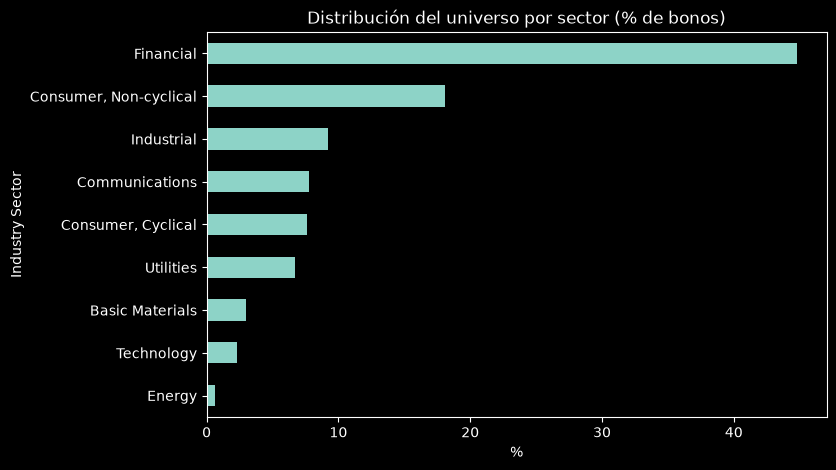

In [33]:
# Gráfico de barras horizontal por sector
sectores['% bonos'].sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Distribución del universo por sector (% de bonos)')
plt.xlabel('%')
plt.show()

In [34]:
# Agrupamos por emisor: nº de bonos y nominal vivo total
emisores = universo.groupby('Issuer').agg(
    n_bonos=('Description', 'count'),
    nominal_total=('Outstanding Amount', 'sum')
)

# Peso de cada emisor en una cartera equiponderada (todos los bonos con el mismo peso)
emisores['% cartera_eq'] = (emisores['n_bonos'] / len(universo) * 100).round(2)

print(f'Número de emisores: {len(emisores)}')
emisores.sort_values('n_bonos', ascending=False).head(15)

Número de emisores: 605


,n_bonos,nominal_total,% cartera_eq
Issuer,,,
BANQUE FED CRED MUTUEL,32,32104000000,1.48
BNP PARIBAS,25,30928000000,1.15
BPCE SA,23,21250000000,1.06
ORANGE SA,22,17350000000,1.02
VOLKSWAGEN INTL FIN NV,21,23050000000,0.97
VONOVIA SE,21,14327800000,0.97
SOCIETE GENERALE,21,22250000000,0.97
NESTLE FINANCE INTL LTD,20,13450000000,0.92
CREDIT AGRICOLE SA,19,21500000000,0.88


In [35]:
# Concentración: peso de los 10 emisores con más bonos
top10 = emisores['n_bonos'].nlargest(10).sum() / len(universo) * 100
print(f'Los 10 mayores emisores suponen el {top10:.1f}% del universo')

Los 10 mayores emisores suponen el 10.3% del universo


#### <font color=#808080>Ratings (Riesgo de crédito)</font>

Rating
AAA       4.0
AA+       6.0
AA       20.0
AA-      96.0
A+      180.0
A       222.0
A-      363.0
BBB+    415.0
BBB     300.0
BBB-    176.0
BB+       8.0
NR      372.0
Name: count, dtype: float64
Bonos sin dato de rating (NaN): 3


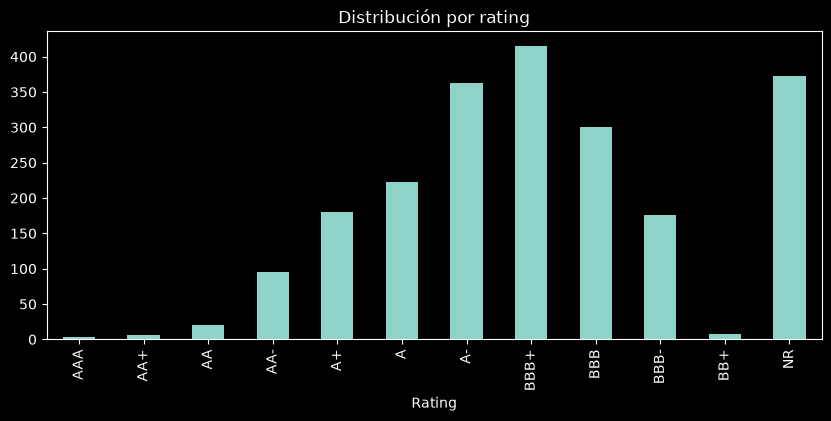

In [36]:
# Escala de ratings de mejor a peor, para ordenar las tablas y gráficos
escala = ['AAA', 'AA+', 'AA', 'AA-', 'A+', 'A', 'A-',
          'BBB+', 'BBB', 'BBB-',                    # hasta aquí: Investment Grade
          'BB+', 'BB', 'BB-', 'B+', 'B', 'B-',      # High Yield
          'NR']                                      # sin rating

# Nº de bonos por rating en el orden de la escala (eliminamos los que no aparecen)
ratings = universo['Rating'].value_counts().reindex(escala).dropna()
print(ratings)
print(f"Bonos sin dato de rating (NaN): {universo['Rating'].isna().sum()}")

ratings.plot(kind='bar', figsize=(10, 4))
plt.title('Distribución por rating')
plt.show()

In [37]:
# Clasificamos cada bono en IG / HY / Sin rating
grado_inversion = escala[:10]   # de AAA a BBB-

def clasificar_rating(rating):
    """Devuelve 'IG', 'HY' o 'Sin rating' según el rating del bono."""
    if pd.isna(rating) or rating == 'NR':
        return 'Sin rating'
    return 'IG' if rating in grado_inversion else 'HY'

universo['Categoria'] = universo['Rating'].apply(clasificar_rating)
universo['Categoria'].value_counts()

Categoria
IG            1782
Sin rating     375
HY               8
Name: count, dtype: int64

In [38]:
# ¿Qué probabilidad de impago a 1 año tiene cada categoría?
universo.groupby('Categoria')['PD 1YR'].describe()


,count,mean,std,min,25%,50%,75%,max
Categoria,,,,,,,,
HY,8.0,0.007917,0.010345,2.872080e-06,0.000026,0.001057,0.020395,0.020395
IG,1765.0,0.003777,0.008857,2.944640e-12,0.000014,0.000118,0.001036,0.063122
Sin rating,369.0,0.002893,0.005606,1.082270e-09,0.000015,0.000298,0.002114,0.031020


#### <font color=#808080>Riesgo de liquidez - Horquillas y nominal vivo</font>

In [39]:
# Horquilla bid-ask en puntos de precio
universo['Horquilla'] = universo['Ask Price'] - universo['Bid Price']

# Nominal vivo en millones, más fácil de leer
universo['Nominal_mill'] = universo['Outstanding Amount'] / 1e6

universo[['Horquilla', 'Nominal_mill']].describe()

,Horquilla,Nominal_mill
count,2165.000000,2165.000000
mean,0.235440,744.580655
std,0.145767,308.231911
min,0.029200,250.003000
25%,0.129300,500.000000
50%,0.201900,700.000000
75%,0.307590,1000.000000
max,1.537550,3000.000000


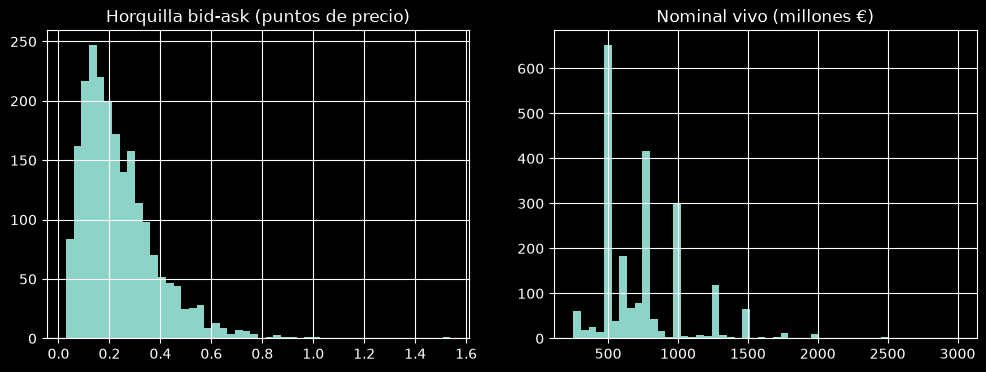

In [40]:
# Histogramas de horquilla y nominal vivo
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

universo['Horquilla'].hist(bins=50, ax=ax[0])
ax[0].set_title('Horquilla bid-ask (puntos de precio)')

universo['Nominal_mill'].hist(bins=50, ax=ax[1])
ax[1].set_title('Nominal vivo (millones €)')

plt.show()

In [41]:
# Horquilla mediana por categoría de rating
print(universo.groupby('Categoria')['Horquilla'].median(), '\n')

# Bonos excluidos por el mandato por tamaño (≤ 500 millones)
pequenos = (universo['Nominal_mill'] <= 500).sum()
print(f'Bonos con nominal ≤ 500M: {pequenos} ({pequenos / len(universo) * 100:.1f}%)')

Categoria
HY            0.12945
IG            0.19921
Sin rating    0.22599
Name: Horquilla, dtype: float64 

Bonos con nominal ≤ 500M: 767 (35.4%)


#### <font color=#808080>Resto de información</font>

En esta sección, analizamos el resto de ficheros para ver qué información tenemos y, en caso de haber *gaps*, limpiar los datos antes de trabajar con ellos.

##### <font color=#CC6600>Precios bonos universo</font>

In [42]:
# Cargamos los precios históricos: filas = bonos, columnas = fechas
precios = pd.read_csv(
    RUTA_DATOS + 'precios_historicos_universo.csv',
    sep=';',
    index_col=0,             # la primera columna (identificador del bono) será el índice
    na_values=['#N/D'],      # marcador de "sin dato" -> NaN
    encoding='utf-8-sig'
)

# Transponemos: filas = fechas, columnas = bonos
precios = precios.T

# Convertimos el índice (texto) a fechas
precios.index = pd.to_datetime(precios.index, format='%d/%m/%Y')

# Los identificadores vienen como 'XS0161488498 Corp': nos quedamos solo con el ISIN
precios.columns = precios.columns.str.replace(' Corp', '', regex=False)

print(precios.shape)
print('¿Mismos bonos que en el universo?', set(precios.columns) == set(universo.index))

(1097, 2165)
¿Mismos bonos que en el universo? True


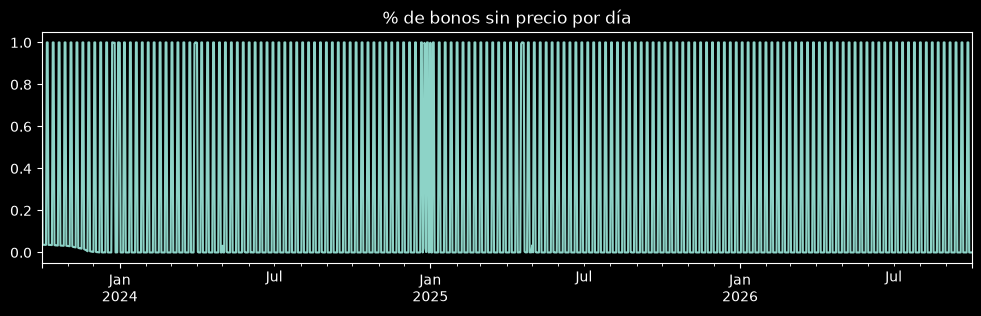

Días sin mercado: 323
Festivos entre semana: ['25/12/2023', '26/12/2023', '01/01/2024', '29/03/2024', '01/04/2024', '25/12/2024', '26/12/2024', '01/01/2025', '18/04/2025', '21/04/2025']


C:\Users\guada\AppData\Local\Temp\ipykernel_21364\748551389.py:13: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  festivos = precios.index[dias_sin_mercado & (precios.index.dayofweek < 5)]


In [43]:
# Porcentaje de bonos sin precio en cada fecha
pct_nan_dia = precios.isna().mean(axis=1)

pct_nan_dia.plot(figsize=(12, 3))
plt.title('% de bonos sin precio por día')
plt.show()

# Días en los que (casi) ningún bono tiene precio: fines de semana y festivos
dias_sin_mercado = pct_nan_dia > 0.9
print(f'Días sin mercado: {dias_sin_mercado.sum()}')

# ¿Cuáles de esos días NO son fin de semana? (dayofweek: 0 = lunes ... 6 = domingo)
festivos = precios.index[dias_sin_mercado & (precios.index.dayofweek < 5)]
print('Festivos entre semana:', list(festivos.strftime('%d/%m/%Y')))

In [44]:
# Eliminamos fines de semana y festivos
precios = precios.loc[~dias_sin_mercado]
print(f'Días hábiles: {len(precios)}')

# ¿Qué bonos empiezan a cotizar más tarde? (emitidos después de oct-2023)
primer_precio = precios.apply(lambda serie: serie.first_valid_index())
emitidos_tarde = primer_precio[primer_precio > precios.index[0]]
print(f'Bonos que empiezan a cotizar después del inicio: {len(emitidos_tarde)}')

# Comprobamos que coinciden con su fecha de emisión
pd.DataFrame({
    'Primer precio': emitidos_tarde,
    'Fecha emisión': universo.loc[emitidos_tarde.index, 'Issue date']
}).head(10)

Días hábiles: 774
Bonos que empiezan a cotizar después del inicio: 79


,Primer precio,Fecha emisión
XS2698045130,2023-10-17,2023-09-29
XS2690050682,2023-10-06,2023-10-12
FR001400LCK1,2023-10-12,2023-10-18
XS2705604234,2023-10-13,2023-10-18
XS2698998593,2023-10-17,2023-10-23
XS2707169111,2023-10-17,2023-10-23
FR001400KSZ7,2023-10-18,2023-10-25
XS2704918478,2023-10-20,2023-10-25
XS2708354811,2023-10-19,2023-10-25
XS2661068234,2023-10-26,2023-10-30


Huecos rellenados: 284


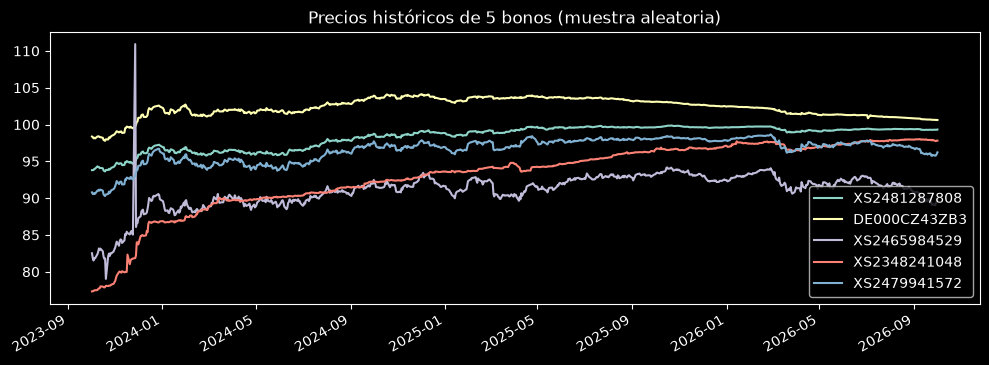

In [45]:
# Rellenamos los huecos puntuales con el último precio disponible
# (ffill no rellena los NaN iniciales: los bonos aún no emitidos siguen sin precio)
huecos_antes = precios.isna().sum().sum()
precios = precios.ffill()
print(f'Huecos rellenados: {huecos_antes - precios.isna().sum().sum()}')

# Evolución de precios de 5 bonos al azar (random_state fija la muestra)
precios.sample(5, axis=1, random_state=42).plot(figsize=(12, 4))
plt.title('Precios históricos de 5 bonos (muestra aleatoria)')
plt.show()

##### <font color=#CC6600>Otros precios</font>

Para terminar con el análisis de datos, falta lo leído en los ficheros de *precios_historicos_varios.csv* y *curvaESTR.csv*.

ITRX EUR CDSI GEN 5Y Corp      15
ITRX XOVER CDSI GEN 5Y Corp    15
DU1 Comdty                     12
OE1 Comdty                     12
RX1 Comdty                     12
RECMTREU Index                  0
dtype: int64
¿Mismas fechas que precios? False


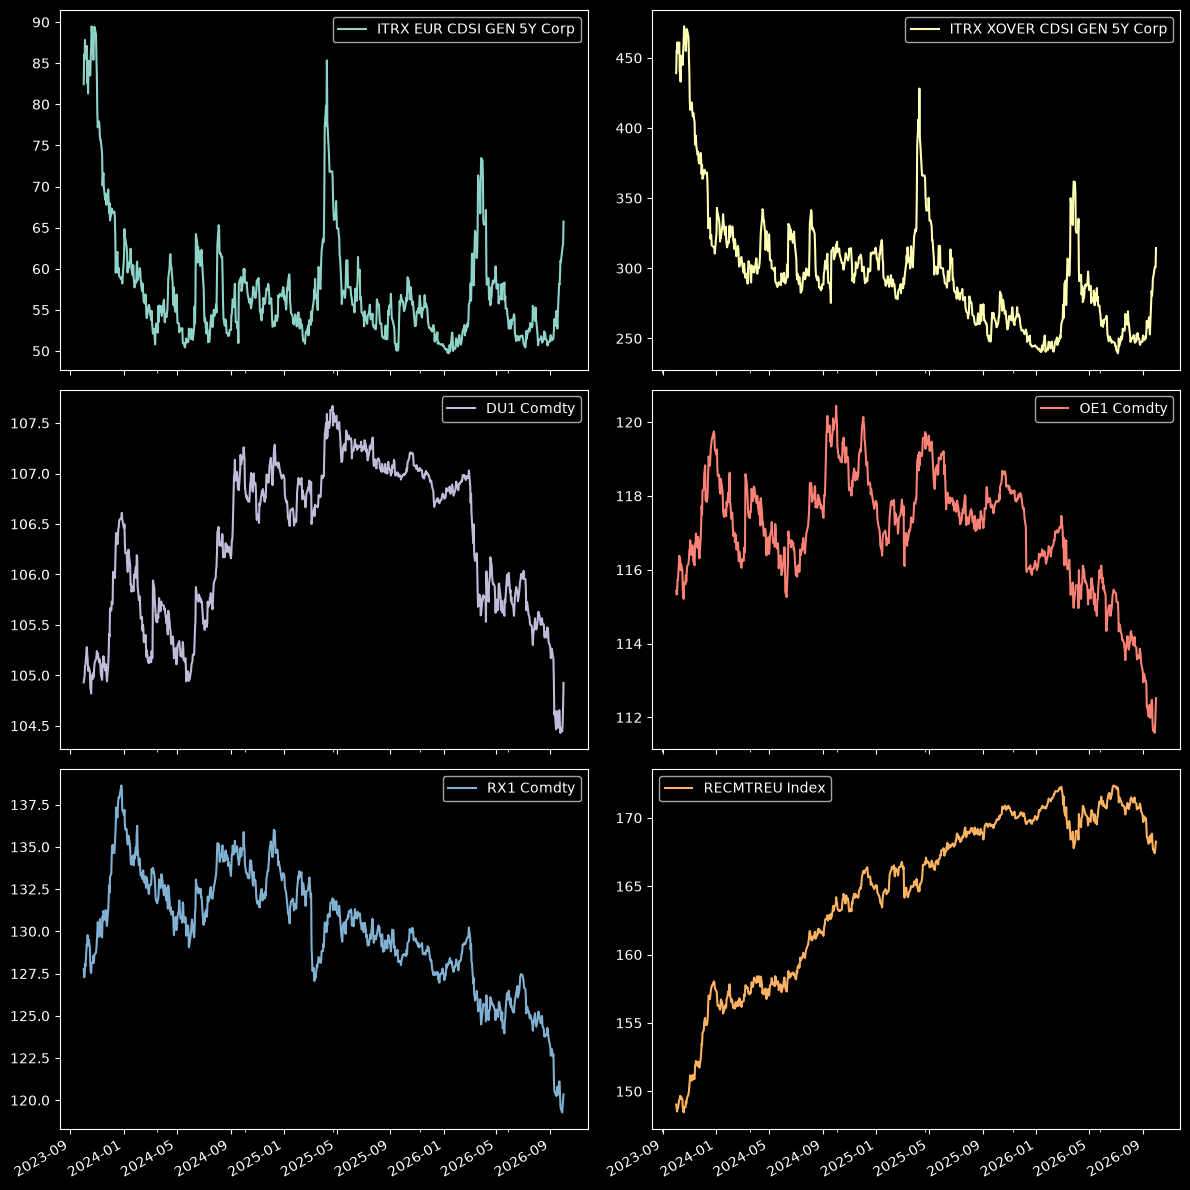

In [46]:
# Cargamos índices de crédito (iTraxx), futuros (DU1, OE1, RX1) y benchmark (RECMTREU)
varios = pd.read_csv(
    RUTA_DATOS + 'precios_historicos_varios.csv',
    sep=';', index_col=0, na_values=['#N/D'], encoding='utf-8-sig'
)
varios.index = pd.to_datetime(varios.index, format='%d/%m/%Y')

# Huecos por serie
print(varios.isna().sum())

# Rellenamos con el último valor disponible
varios = varios.ffill()

# ¿Las fechas coinciden con las de los precios de los bonos?
print('¿Mismas fechas que precios?', varios.index.equals(precios.index))

# Un gráfico por serie (escalas muy distintas)
varios.plot(subplots=True, figsize=(12, 12), layout=(3, 2))
plt.tight_layout()
plt.show()

Diferencia máxima: 6.765132900543591e-07


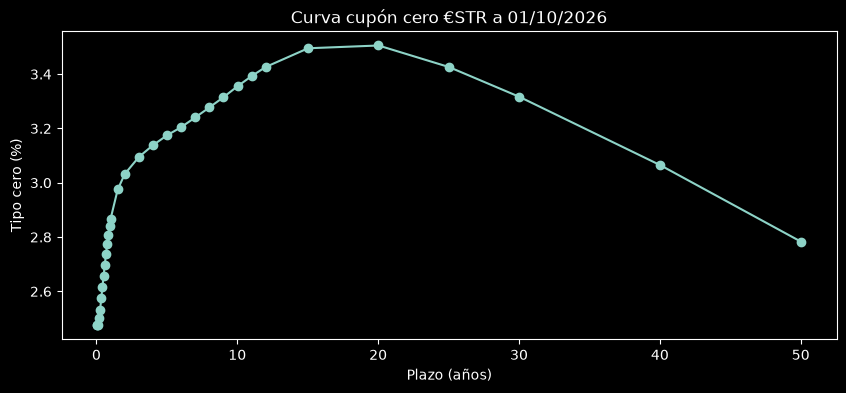

In [47]:
# Cargamos la curva €STR a 01/10/2026
curva = pd.read_csv(RUTA_DATOS + 'curvaESTR.csv', sep=';')
curva['Date'] = pd.to_datetime(curva['Date'], format='%d/%m/%Y')

# Plazo en años desde la fecha de análisis (base Act/365)
curva['Plazo'] = (curva['Date'] - fecha_analisis).dt.days / 365

# Comprobación: ¿el factor de descuento sale de capitalización continua?  DF = exp(-z·t)
curva['DF_check'] = np.exp(-curva['Zero Rate'] / 100 * curva['Plazo'])
print('Diferencia máxima:', (curva['DF_check'] - curva['Discount']).abs().max())

# Gráfico de la curva cero
curva.plot(x='Plazo', y='Zero Rate', marker='o', figsize=(10, 4), legend=False)
plt.title('Curva cupón cero €STR a 01/10/2026')
plt.xlabel('Plazo (años)')
plt.ylabel('Tipo cero (%)')
plt.show()

#### <font color=#808080>Conclusiones</font>

### <font color=#336699>2. Valoración</font>

**Valoración de los bonos del universo** utilizando la curva de descuento y bajo ciertas asunciones. Comparación de estos precios con los precios de mercado.

En esta sección, valoraremos los bonos utilizando la curva. Para ello, crea una función (puedes hacerlo en un .py aparte) que con las **características del bono, la curva y un spread de crédito** para que devuelva la valoración del bono (incluyendo **precio limpio, cupón corrido y precio sucio**).

Si asumimos que el **spread de crédito es 0**, y la ejecutamos para el 01/10/2026:
- ¿Qué observas si comparas los precios obtenidos y los precios de mercado? 
- ¿Crees que la diferencia se debe a un factor relacionado sólo con el riesgo crediticio?
- ¿Qué otros factores influyen en ese spread?

Para la valoración, haz las siguientes simplificaciones:

- Asume que el vencimiento de los bonos perpetuos (para los que no hay vencimiento) es la próxima fecha call.
- Asume que todos aquellos bonos que tengan call serán calleados. Por lo tanto, usa la fecha call como fecha de vencimiento.
- Asume que los cupones son fijos hasta vencimiento (aunque alguno cambie a lo largo de la vida del bono).
- Usa la base de cálculo ACT/365. No tengas en cuenta la convención de día hábil.

Ten en cuenta que necesitarás una función de interpolación también. Interpola los factores de descuento exponencialmente.

**Guarda en "results" una tabla llamada "valoracion.csv" que contenga:**

- ISIN
- PrecioMercado
- PrecioSucioCalculado
- CuponCorrido
- PrecioLimpioCalculado
- DiferenciaMecadoCalculo
- DiferenciaPct


In [48]:
# Establecemos la fecha
fecha_valor = datetime.datetime(2026,10,1)

In [49]:
# Convertimos la fecha de valoración al tipo de fecha de pandas
fecha_valor = pd.Timestamp(fecha_valor)

# Calculamos el vencimiento efectivo de cada bono (fila a fila: axis=1)
universo['Vto_efectivo'] = universo.apply(
    lambda bono: fa.fecha_vencimiento_efectiva(bono, fecha_valor), axis=1
)

# Comprobación: los 11 bonos con la fecha call ya pasada
call_pasada = universo['Next Call Date'] <= fecha_valor
universo.loc[call_pasada, ['Description', 'Next Call Date', 'Maturity', 'Vto_efectivo']]

,Description,Next Call Date,Maturity,Vto_efectivo
ISIN,,,,
XS1186176571,HTHROW 1 ½ 02/11/30,2026-02-11,2030-02-11,2027-02-11
XS1405762805,TKAAV 1 ½ 12/07/26,2026-09-07,2026-12-07,2026-12-07
XS1531347661,BDX 1.9 12/15/26,2026-09-15,2026-12-15,2026-12-15
XS1532779748,ZBH 2.425 12/13/26,2026-09-13,2026-12-13,2026-12-13
FR0013302809,SUFP 0 ⅞ 12/13/26,2026-09-13,2026-12-13,2026-12-13
XS2081500907,FCCSER 1.661 12/04/26,2026-09-23,2026-12-04,2026-12-04
XS2193974701,WMG 2 ¾ 07/15/28,2025-11-28,2028-07-15,2027-01-15
XS2367081523,WMG 2 ¼ 08/15/31,2026-08-15,2031-08-15,2027-02-15
FR0014005EJ6,BNFP 1 PERP,2026-09-16,NaT,2026-12-16


Valorados a fecha call: 1575
Plazo efectivo mínimo (años): 0.014


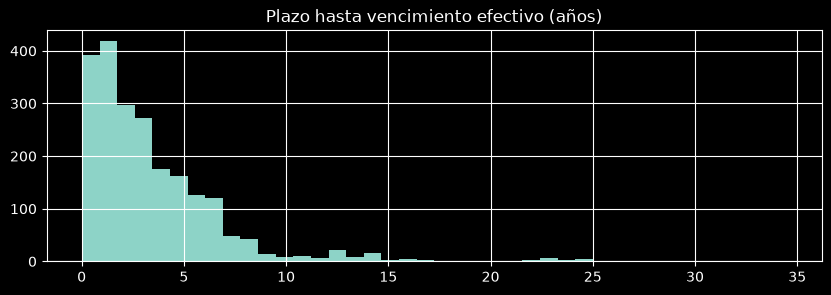

In [50]:
# Plazo efectivo en años (ACT/365) y número de bonos según el tipo de vencimiento
universo['Plazo_efectivo'] = (universo['Vto_efectivo'] - fecha_valor).dt.days / 365

print('Valorados a fecha call:', (universo['Vto_efectivo'] != universo['Maturity']).sum())
print('Plazo efectivo mínimo (años):', universo['Plazo_efectivo'].min().round(3))
universo['Plazo_efectivo'].hist(bins=40, figsize=(10, 3))
plt.title('Plazo hasta vencimiento efectivo (años)')
plt.show()

**Vencimiento efectivo.** Siguiendo el enunciado, los bonos callable (y los perpetuos) se valoran a su próxima fecha call. En 11 bonos la fecha call ya ha pasado (la opción ya es ejercitable): asumimos que se amortizan en la **próxima fecha de cupón**. En total, 1.575 bonos se valoran a fecha call en lugar de a vencimiento.

In [52]:
# 1) En los nodos de la curva, la interpolación debe devolver exactamente sus DF
df_nodos = fa.factor_descuento(curva['Plazo'], curva)
print('Error máximo en los nodos:', np.abs(df_nodos - curva['Discount']).max())

# 2) Un punto intermedio: 2 años (entre los nodos de oct-2028 y oct-2029)
print('DF a 2 años:', fa.factor_descuento(2.0, curva))

Error máximo en los nodos: 2.7755575615628914e-17
DF a 2 años: 0.9411790129324283


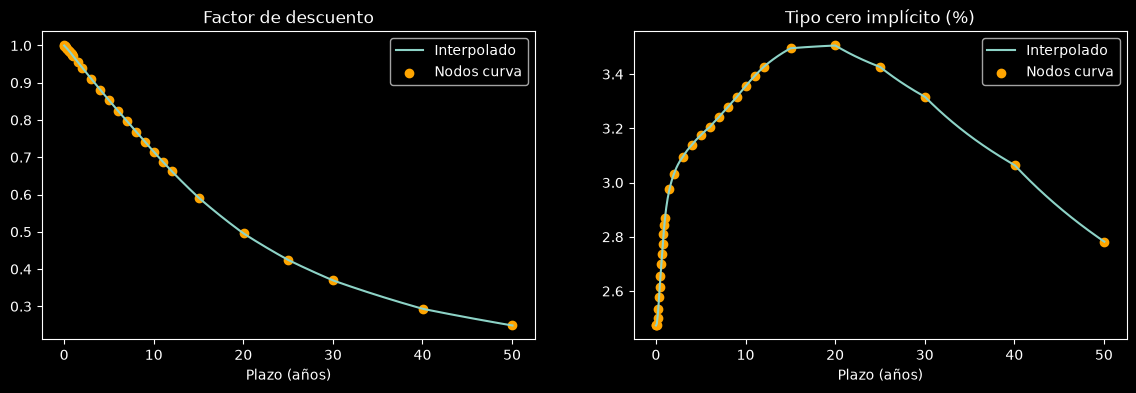

In [53]:
# 3) Curva interpolada en una malla fina de plazos (de 1 día a 50 años)
plazos = np.linspace(1/365, curva['Plazo'].max(), 1000)
df_interp = fa.factor_descuento(plazos, curva)

# Tipo cero implícito en capitalización continua: z = -ln(DF) / t
cero_interp = -np.log(df_interp) / plazos * 100

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].plot(plazos, df_interp, label='Interpolado')
ax[0].scatter(curva['Plazo'], curva['Discount'], color='orange', label='Nodos curva')
ax[0].set_title('Factor de descuento')
ax[0].set_xlabel('Plazo (años)')
ax[0].legend()

ax[1].plot(plazos, cero_interp, label='Interpolado')
ax[1].scatter(curva['Plazo'], curva['Zero Rate'], color='orange', label='Nodos curva')
ax[1].set_title('Tipo cero implícito (%)')
ax[1].set_xlabel('Plazo (años)')
ax[1].legend()

plt.show()

In [54]:
# Probamos con tres bonos representativos:
#  - DT 7½ 2033: sin call, cupón anual
#  - ARRFP 1¼ 2027: call (06/10/2026) entre dos fechas de cupón
#  - WMG 2¾ 2028: semestral, call pasada -> próximo cupón
for isin in ['XS0161488498', 'FR0013220258', 'XS2193974701']:
    bono = universo.loc[isin]
    print(bono['Description'], '| vencimiento efectivo:', bono['Vto_efectivo'].date())
    display(fa.flujos_bono(bono, fecha_valor))

DT 7 ½ 01/24/33 | vencimiento efectivo: 2033-01-24


,Fecha,Plazo,Flujo
0,2027-01-24,0.315068,7.5
1,2028-01-24,1.315068,7.5
2,2029-01-24,2.317808,7.5
3,2030-01-24,3.317808,7.5
4,2031-01-24,4.317808,7.5
5,2032-01-24,5.317808,7.5
6,2033-01-24,6.320548,107.5


ARRFP 1 ¼ 01/06/27 | vencimiento efectivo: 2026-10-06


,Fecha,Plazo,Flujo
0,2026-10-06,0.013699,100.934932


WMG 2 ¾ 07/15/28 | vencimiento efectivo: 2027-01-15


,Fecha,Plazo,Flujo
0,2027-01-15,0.290411,101.375


In [55]:
# Comprobamos que la función funciona para TODOS los bonos (sin errores)
n_flujos = universo.apply(lambda bono: len(fa.flujos_bono(bono, fecha_valor)), axis=1)
print(n_flujos.describe())

count    2165.000000
mean        4.024018
std         3.355187
min         1.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        35.000000
dtype: float64


In [56]:
# Valoramos el DT 7½ 2033 con spread 0 y con spread de 100 pb
bono = universo.loc['XS0161488498']

print('Spread 0:     ', fa.valorar_bono(bono, curva, fecha_valor))
print('Spread 100 pb:', fa.valorar_bono(bono, curva, fecha_valor, spread=0.01))
print('Precio de mercado (limpio):', bono['Price'])

Spread 0:      {'PrecioSucio': np.float64(129.00518601183234), 'CuponCorrido': np.float64(5.136986301369863), 'PrecioLimpio': np.float64(123.86819971046248)}
Spread 100 pb: {'PrecioSucio': np.float64(122.52927657488459), 'CuponCorrido': np.float64(5.136986301369863), 'PrecioLimpio': np.float64(117.39229027351473)}
Precio de mercado (limpio): 117.874


In [57]:
# Valoramos todos los bonos del universo con spread 0
# pd.Series(...) convierte el diccionario de cada bono en una fila con 3 columnas
valores = universo.apply(
    lambda bono: pd.Series(fa.valorar_bono(bono, curva, fecha_valor)), axis=1
)

# Construimos la tabla de resultados con las columnas que pide el enunciado
valoracion = pd.DataFrame({
    'PrecioMercado': universo['Price'],
    'PrecioSucioCalculado': valores['PrecioSucio'],
    'CuponCorrido': valores['CuponCorrido'],
    'PrecioLimpioCalculado': valores['PrecioLimpio'],
})

# Diferencia mercado - cálculo (en puntos de precio y en % sobre el precio de mercado)
valoracion['DiferenciaMecadoCalculo'] = valoracion['PrecioMercado'] - valoracion['PrecioLimpioCalculado']
valoracion['DiferenciaPct'] = valoracion['DiferenciaMecadoCalculo'] / valoracion['PrecioMercado'] * 100

valoracion.index.name = 'ISIN'
valoracion.describe().round(3)

,PrecioMercado,PrecioSucioCalculado,CuponCorrido,PrecioLimpioCalculado,DiferenciaMecadoCalculo,DiferenciaPct
count,2165.000,2165.000,2165.000,2165.000,2165.000,2165.000
mean,94.417,98.473,1.109,97.363,-2.946,-3.385
std,8.136,7.356,1.157,6.728,3.038,4.194
min,43.103,59.429,0.000,59.426,-21.090,-43.559
25%,91.554,94.982,0.307,94.556,-4.038,-4.467
50%,96.924,99.178,0.735,98.430,-1.952,-2.006
75%,99.506,102.727,1.450,100.882,-0.881,-0.897
max,121.400,132.907,8.225,127.431,9.652,9.618


In [60]:
import os

# Creamos la carpeta results si no existe y guardamos la tabla
os.makedirs(RUTA_RESULTS, exist_ok=True)
valoracion.to_csv(RUTA_RESULTS + 'valoracion.csv', sep=';')
print('Guardado:', os.path.abspath(RUTA_RESULTS + 'valoracion.csv'))

Guardado: c:\Users\guada\Downloads\RF_MIAX15\Taller_RF_MIAX15\results\valoracion.csv


Bonos con precio de mercado < precio calculado: 99.8%


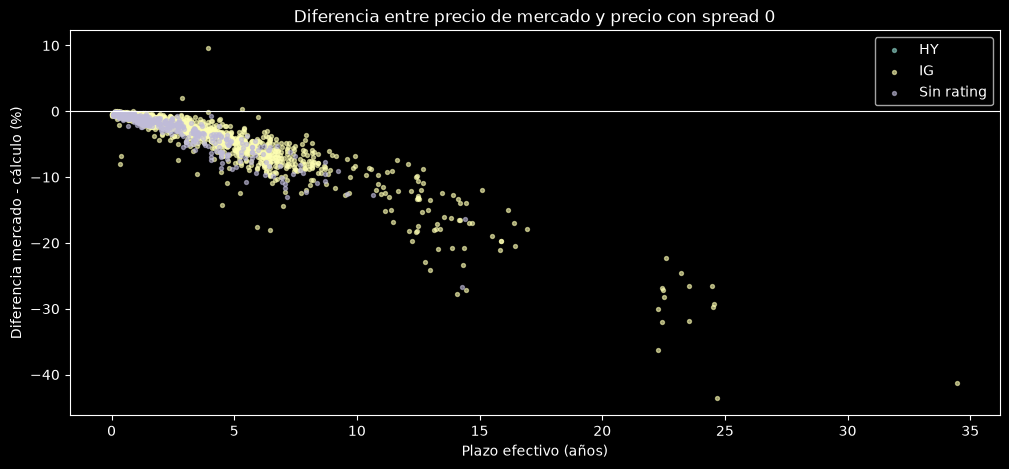

In [61]:
# ¿Cuántos bonos cotizan por debajo del precio calculado con spread 0?
por_debajo = (valoracion['DiferenciaMecadoCalculo'] < 0).mean() * 100
print(f'Bonos con precio de mercado < precio calculado: {por_debajo:.1f}%')

# Añadimos plazo y categoría de rating para analizar la diferencia
analisis = valoracion.join(universo[['Plazo_efectivo', 'Categoria', 'Seniority', 'Industry Sector']])

# Diferencia (%) frente al plazo efectivo, coloreada por categoría de rating
fig, ax = plt.subplots(figsize=(12, 5))
for categoria, grupo in analisis.groupby('Categoria'):
    ax.scatter(grupo['Plazo_efectivo'], grupo['DiferenciaPct'], s=8, label=categoria, alpha=0.6)
ax.axhline(0, color='white', linewidth=0.8)
ax.set_xlabel('Plazo efectivo (años)')
ax.set_ylabel('Diferencia mercado - cálculo (%)')
ax.set_title('Diferencia entre precio de mercado y precio con spread 0')
ax.legend()
plt.show()

In [62]:
# Diferencia mediana (%) por prelación y por sector
print(analisis.groupby('Seniority')['DiferenciaPct'].median().sort_values().round(2), '\n')
print(analisis.groupby('Industry Sector')['DiferenciaPct'].median().sort_values().round(2))

Seniority
1st lien           -4.78
Subordinated       -2.30
Sr Unsecured       -2.26
Jr Subordinated    -2.19
Secured            -1.93
Sr Non Preferred   -1.20
Sr Preferred       -0.80
Name: DiferenciaPct, dtype: float64 

Industry Sector
Energy                   -3.43
Communications           -3.05
Basic Materials          -2.77
Utilities                -2.54
Consumer, Non-cyclical   -2.10
Industrial               -2.10
Technology               -1.97
Consumer, Cyclical       -1.73
Financial                -1.72
Name: DiferenciaPct, dtype: float64


### <font color=#336699>3. Spread</font>

**Cálculo del z-spread** que pagan los bonos sobre la curva.

Calculemos ahora los spreads que debemos añadir a la curva con un movimiento paralelo para que cuadren los precios de mercado que tenemos. Para ello, usa la función de valoración del apartado anterior. 
- ¿Qué observas? ¿Tienen sentido los resultados? 
- ¿Con qué datos de los que tenemos compararías para ver si los resultados son coherentes?

**Guarda en "results" una tabla llamada "spread.csv" que contenga:**

- ISIN
- Spread
- PrecioSpreadCero
- PrecioSpreadCalculado

### <font color=#336699>4. Yield, Duración, Convexidad</font>

Cálculo de **yield, duración y convexidad**.

Calculemos ahora la siguiente información, también relacionada con la rentabilidad y riesgo de las emisiones:
- *Yield* - Por simplicidad, en este caso, en el caso de los bonos callable, nos quedaremos con la fecha call, como en el ejercicio anterior. Usa las mismas asunciones que para la valoración y el spread.
- Duración
- Convexidad

Responde a las siguientes preguntas:
- ¿Que relación hay entre la *yield* calculada y el spread calculado en el apartado anterior?
- ¿Qué relación hay entre la duración y el vencimiento? ¿Qué refleja la duración? ¿De qué otra forma se podría obtener esta sensibilidad?
- Estima la variación del precio de los bonos ante una caída de un 1% de la *yield* usando la duración y convexidad, ¿qué observas?

**Guarda en "results" una tabla llamada "sensibilidad.csv" que contenga:**

- ISIN
- Yield
- Dur
- ModDur
- Convexidad
- VarPrecioDurConv

### <font color=#336699>5. Cartera equiponderada</font>

**Contrucción de una cartera equiponderada** con todos los bonos del universo. Contraste con el benchmark (os proponemos el índice RECMTREU para el que os hemos dado los precios) y backtest de la estrategia. ¡OJO! El índice es *Total Return*.

Crea un algoritmo de inversión que consista en una cartera equiponderada, asignando el mismo peso a todos los bonos vivos en cada fecha de rebalanceo.

Asume rebalanceo mensual, y que no tenemos costes más allá de los implícitos en el propio precio. Calcula la evolución que hubiese tenido tu algoritmo. Por simplificación, utiliza los precios MID que se te dan.

- ¿Qué sería lo más correcto en lugar de utilizar los precios MID?
- ¿Se te ocurre algún otro benchmark que se podría utilizar?

**Guarda en "results" una tabla llamada "backtest_equal_weight.csv" que contenga:**

- Fecha Mes
- Rent cartera
- Rent benchmark
- Dif


### <font color=#336699>6. Cartera mandato</font>

Tienes el mandato de **construir una cartera** de como máximo **20** bonos corporativos con ese universo y una serie de restricciones y, claro, maximizando la rentabilidad total de la cartera:
- La duración de la cartera no debe superar los 3 años
- La exposición a emisiones HY no puede superar el 10% de la cartera
- No puedes invertir en deuda subordinada
- No se puede invertir en emisiones de tamaño igual o inferior a 500 millones
- No se puede invertir más de un 10% del capital en una misma emisión
- No puede haber más de un 15% de concentración en un mismo emisor
(¡OJO! No estamos teniendo en cuenta en este ejercicio si hubiera un mínimo de inversión, lo cuál sería un dato relevante tener en cuenta en un caso real)

1. Constrúyela a fecha 1/10/2026

2. Teniendo en cuenta la naturaleza que nos están pidiendo para la cartera, ¿añadirías alguna otra restricción?

3. ¿Cómo medirías el riesgo de crédito de la cartera?

4. ¿Cómo medirías el riesgo de liquidez de la cartera? ¿Se te ocurre alguna otra información que se podría utilizar aunque no se te haya dado?

5. Describe cómo habría que hacer el backtest de esta cartera (no hace falta que lo implementes en este caso).


**Guarda en "results" una tabla llamada "cartera_optima.csv" que contenga:**

- ISIN
- Peso
- Yield
- Duration
- Rating
- Issuer
- Outstanding Amount
- Seniority
- Industry Sector

Y UNA FILA CON ISIN "CARTERA" CON LA DURACIÓN Y LA YIELD DE LA CARTERA RESULTANTE

##### <font color=#CC6600>Riesgo de crédito</font>

##### <font color=#CC6600>Riesgo de liquidez</font>

##### <font color=#CC6600>Backtest</font>

### <font color=#336699>7. Cobertura tipos de interés</font>

**Cubre la exposición de la cartera a los tipos de interés.**

Utiliza alguno de los siguientes instrumentos para cubrir la duración (sensibilidad de tipos de interés) de la cartera que has construido según el mandato. Asume una inversión en la cartera de 10 millones:

- Futuros sobre el *Schatz* (ticker: DU1) - Duración a 01/10/2026: 1.92
- Futuros sobre el *BOBL* (ticker: OE1) - Duración a 01/10/2026: 5.44
- Futuros sobre el *BUND* (ticker: RX1) - Duración a 01/10/2026: 10

*Contract size* en todos los casos: 100,000 euros

Investiga sobre estos instrumentos antes de tomar la decisión. Razona tu elección del instrumento y el número de contratos que has decidido comprar/vender.

- ¿Qué pasaría si comprásemos/vendiésemos 100 futuros?
- ¿Se te ocurre algún otro instrumento con el que cubrir la sensibilidad a los tipos de interés de la cartera?


### <font color=#336699>8. Cobertura crédito</font>

**Cubre total o parcialmente el riesgo de crédito.**

Utiliza alguno de los siguientes instrumentos para cubrir el riesgo de crédito de la cartera que has construido según el mandato. Asume una inversión en la cartera de 10 millones€:

- ITRAXX Main (ticker: ITRX EUR CDSI GEN 5Y Corp)
- ITRAXX XOVER (ticker: ITRX XOVER CDSI GEN 5Y Corp)

Estos índices cotizan en forma de spread, en puntos básicos. La sensibilidad del valor del CDS es de 4,500€ al punto básico, asumiendo una inversión de 10 millones€.

Investiga sobre estos instrumentos antes de tomar la decisión. Razona tu elección del instrumento y el nominal que has decidido comprar/vender.

- ¿Tiene sentido plantear esta cobertura total?
- ¿Con qué otros instrumentos podrías cubrir el riesgo de crédito?
- ¿Qué riesgos permanecen después de la cobertura? Menciona al menos 3 y razónalos.


### <font color=#336699>9. Stress Test</font>

<style>.gray {background-color: #595959}

</style><div class="gray">

Teniendo en cuenta los siguientes escenarios de estrés:
- **Escenario A: shock de tipos**: movimiento de tipos a la alza de 100 pbs.
- **Escenario B: shock de crédito**: movimiento del spread de crédito (50 pbs para bonos *high yield* y 150 pbs para bonos *investment grade*).
- **Escenario C: crisis**: escenario conjunto de tipos y crédito.

Estima el impacto de cada escenario en la cartera a fecha 01/10/2026. Asume una inversión de 100 millones.

**Guarda en "results" una tabla llamada "stress_test.csv" que contenga el valor de la cartera y P&L en cada escenario incluyendo el escenario base de no estrés:**

- Escenario
- ValorCartera
- P&L

</div>